<a href="https://colab.research.google.com/github/khanni1/Machine_learning/blob/clg/log_e/testing_log_reg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset:
    x0        x1        x2        x3        x4        x5        x6  y
0  1.0  1.728717 -4.188508  4.514907  3.384918  3.050903  3.229838  1
1  1.0  0.993597  2.286563 -1.846363 -1.068529 -2.630760 -4.030343  0
2  1.0  3.743073  3.306228 -2.753426 -1.006674 -0.903271  4.782207  1
3  1.0  0.739499 -1.071049 -4.713476  0.832524 -4.886975  2.873720  0
4  1.0 -1.048623 -4.605405 -0.244540  0.430246 -2.722503  4.640288  1

Dataset shape: (1000, 8)

Accuracy: 92.5 %


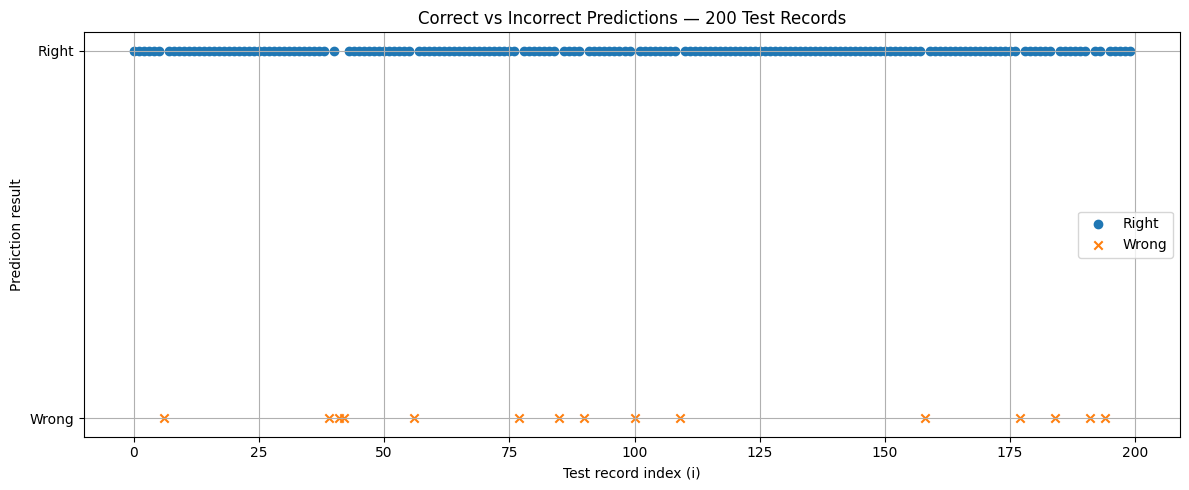

In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Generate 1000 records with 6 random features
np.random.seed(42)

n = 1000

x = np.random.uniform(-5, 5, size=(n, 6))

# x0 is always 1
x = np.column_stack((np.ones(n), x))

# 2. Generate corresponding binary y values
# Create a learnable relationship between features and target
a = np.array([0, 1.2, -0.8, 0.9, -1.1, 0.7, 1.0])

z = x @ a
prob = 1 / (1 + np.exp(-z))

y = (np.random.random(n) < prob).astype(int)

# 3. Create DataFrame
cols = ['x0', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6']

df = pd.DataFrame(x, columns=cols)
df['y'] = y

# Shuffle records so they are unordered
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Dataset:")
print(df.head())
print("\nDataset shape:", df.shape)

# 4. Split using head(800) and remaining 200 records
train = df.head(800)
test = df.tail(200)

X_train = train[cols].to_numpy()
y_train = train['y'].to_numpy()

X_test = test[cols].to_numpy()
y_test = test['y'].to_numpy()

# 5. Scale x1-x6; preserve x0 as 1
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[:, 1:] = scaler.fit_transform(X_train[:, 1:])
X_test_scaled[:, 1:] = scaler.transform(X_test[:, 1:])

# 6. Train built-in logistic regression
model = LogisticRegression(fit_intercept=False, max_iter=1000)
model.fit(X_train_scaled, y_train)

# 7. Predict classes for 200 test records
y_pred = model.predict(X_test_scaled)

print("\nAccuracy:", accuracy_score(y_test, y_pred) * 100, "%")

# 8. Plot actual vs predicted class for each test record
# Compare actual vs predicted
correct = (y_test == y_pred)

plt.figure(figsize=(12, 5))

i = np.arange(len(y_test))

plt.scatter(i[correct], np.ones(np.sum(correct)),
            label='Right', marker='o')

plt.scatter(i[~correct], np.zeros(np.sum(~correct)),
            label='Wrong', marker='x')

plt.xlabel("Test record index (i)")
plt.ylabel("Prediction result")
plt.title("Correct vs Incorrect Predictions — 200 Test Records")

plt.yticks([0, 1], ['Wrong', 'Right'])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



[-0.14310242  7.62915799 -5.14515908  5.43734939 -6.42213902  4.12613241
  6.48923594]
Testing accuracy: 92.5 %


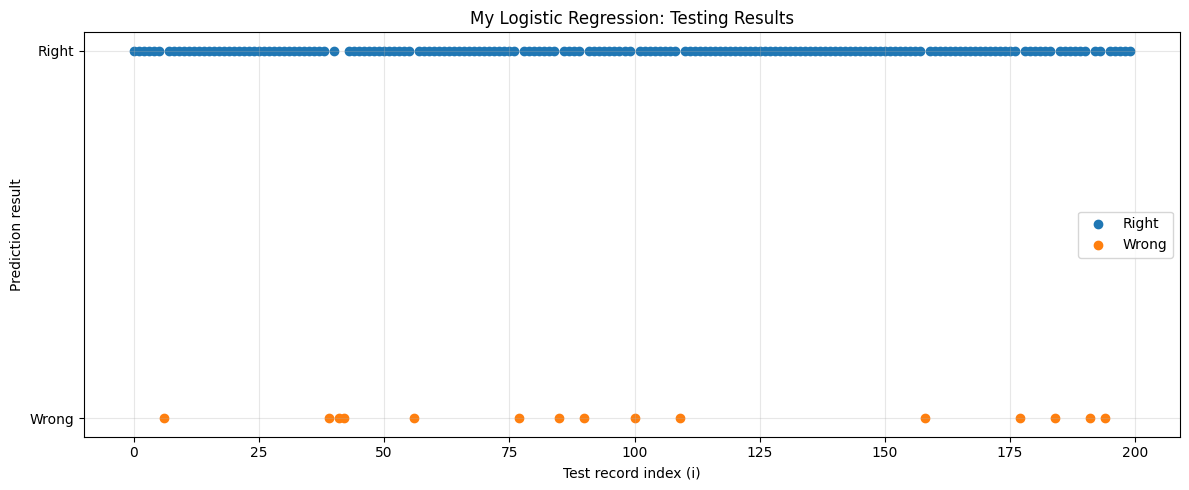

In [16]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def mean_normalise(x,type = 1):
    mu = np.mean(x)

    if(np.all(x == 1)):
        return x

    range = max(x) - min(x)
    stddev = np.std(x)

    if type:
        if range == 0:
            return x - mu
        xn = (x - mu) / range
    else:
        if stddev == 0:
            return x - mu
        xn = (x - mu) / stddev

    return xn

'''
if i/p in this form
rows as records (i) till m
and cols as features (j) till n (1 added as x0)

x = np.array([
    [1,  2.1,  1.0,  0.5,  3.2],
    [1,  1.5,  2.3,  1.1,  2.8],
    [1,  3.2,  0.7,  0.2,  4.1],
    [1,  0.8,  1.9,  2.4,  1.0],
    [1,  2.9,  1.2,  0.9,  3.6],
    [1, -0.5,  2.8,  1.7,  0.4],
'''

def bulk_scale(x):
    x = x.T

    n = len(x)


    x_fs = x.copy()

    # skipped x[0] as all are 1 and to be kept 1
    for j in range(1,n):
        x_fs[j] = mean_normalise(x[j])

    return (x_fs.T)


def sig(a,x):
    ans = 1/(1+np.exp(-z(a,x)))
    return ans



def z(a,x):
    ans = a @ x
    return ans



n = 7  #number of features

a = np.zeros(n)
ta = np.zeros(n )

x = train[cols].to_numpy()
y = train['y'].to_numpy()

X_test = test[cols].to_numpy()
y_test = test['y'].to_numpy()



m = len(y)

# ytwfe6qetf

mu  = x.mean(axis=0)
rng = x.max(axis=0) - x.min(axis=0)
mu[0], rng[0] = 0, 1

x = (x - mu) / rng


al = 1

for k in range(0,1000):
    for j in range(0,n,1):
        summ = 0
        for i in range(0,m,1):
            summ = summ + ((sig(a,x[i]) - y[i])*x[i][j])
        ta[j] = a[j] - ((al/m) * summ)
    a = ta.copy()


print(a)

#  just testing=======================

# Testing: scale with TRAINING mu and range
X_test = (X_test - mu) / rng

prob = np.array([sig(a, X_test[i]) for i in range(len(y_test))])
y_pred = (prob >= 0.5).astype(int)
correct = (y_pred == y_test)

print("Testing accuracy:", np.mean(correct) * 100, "%")

# Plot Right vs Wrong
i = np.arange(len(y_test))

plt.figure(figsize=(12, 5))
plt.scatter(i[correct], np.ones(np.sum(correct)), label="Right")
plt.scatter(i[~correct], np.zeros(np.sum(~correct)), label="Wrong")
plt.xlabel("Test record index (i)")
plt.ylabel("Prediction result")
plt.title("My Logistic Regression: Testing Results")
plt.yticks([0, 1], ["Wrong", "Right"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()